# Notebook for finetuning pretrained Alberta model on desired attention maps - DEPRACTED

## Check the finetune_model_with_atom_map_xent script within the scripts directory for up-to-date code :) 


- This is just a proof of concept. 
- This notebook should be scripted and a full sweep should be run the parameters. 

In [1]:
import pandas as pd
from transformers import AlbertForMaskedLM, AlbertConfig
from rxnmapper.tokenization_smiles import SmilesTokenizer
import torch
import matplotlib.pyplot as plt
import numpy as np
from torch.utils.data import Dataset, DataLoader
import shutil

/home/sacharfd/miniconda3/envs/rxnmapper_v2/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Loading the dataset: 

In [2]:
data_path = "../data/Cyclisation/clean_no_h/cleaned_data_with_attention_maps.json"
data = pd.read_json(data_path)
data.head(5)

,rxn_atom_mapped,rxn,full_rxn_maps
0,[CH3:1][CH2:2][O:3][C:4](=[O:5])[C@@H:6]1[CH2:...,CCOC(=O)[C@@H]1CCc2cc(OS(=O)(=O)C(F)(F)F)cc(=O...,"[0, 52, 51, 50, 48, 0, 0, 46, 0, 56, 0, 55, 53..."
1,[CH3:1][CH2:2][O:3][C:4](=[O:5])[C@@H:6]1[CH2:...,CCOC(=O)[C@@H]1CCc2cc(OS(=O)(=O)C(F)(F)F)cc(=O...,"[0, 46, 47, 49, 50, 0, 0, 53, 0, 55, 0, 58, 59..."
2,[CH3:1][CH2:2][O:3][C:4](=[O:5])[C@@H:6]1[CH2:...,CCOC(=O)[C@@H]1CCc2cc(OS(=O)(=O)C(F)(F)F)cc(=O...,"[0, 46, 47, 48, 49, 0, 0, 52, 0, 54, 0, 57, 58..."
3,[CH3:1][CH2:2][O:3][C:4](=[O:5])[C@@H:6]1[CH2:...,CCOC(=O)[C@@H]1CCc2cc(OS(=O)(=O)C(F)(F)F)cc(=O...,"[0, 52, 51, 50, 48, 0, 0, 46, 0, 88, 0, 53, 55..."
4,[CH3:1][CH2:2][O:3][C:4](=[O:5])[C@@H:6]1[CH2:...,CCOC(=O)[C@@H]1CCc2cc(OS(=O)(=O)C(F)(F)F)cc(=O...,"[0, 46, 47, 49, 50, 0, 0, 53, 0, 55, 0, 57, 58..."


## Loading the RXNMapper Tokeniser: 

In [3]:
vocab_path = "../rxnmapper/models/transformers/albert_heads_8_uspto_all_1310k/vocab.txt"
tokenizer = SmilesTokenizer(vocab_path)


# Tokenise an example rxn:
example_rxn, example_full_map = data["rxn"][0], data["full_rxn_maps"][0]
example_rxn_tokenized = tokenizer(example_rxn, add_special_tokens=True).input_ids

print(example_rxn_tokenized)
print(example_full_map)


# Check with for loop:
for idx in range(data.shape[0]):
    example_rxn, example_full_map = data["rxn"][idx], data["full_rxn_maps"][idx]
    example_rxn_tokenized = tokenizer(example_rxn, add_special_tokens=True).input_ids
    assert len(example_rxn_tokenized) == len(
        example_full_map
    ), f"Index: {idx} , {len(example_full_map)}, {len(example_rxn_tokenized)}"

[12, 16, 16, 19, 16, 17, 22, 19, 18, 35, 20, 16, 16, 15, 21, 15, 15, 17, 19, 34, 17, 22, 19, 18, 17, 22, 19, 18, 16, 17, 27, 18, 17, 27, 18, 27, 18, 15, 15, 17, 22, 19, 18, 25, 21, 20, 29, 19, 22, 16, 20, 19, 16, 16, 16, 21, 16, 35, 20, 25, 20, 15, 21, 15, 15, 17, 19, 34, 17, 22, 19, 18, 17, 22, 19, 18, 16, 17, 27, 18, 17, 27, 18, 27, 18, 15, 15, 20, 22, 19, 13]
[0, 52, 51, 50, 48, 0, 0, 46, 0, 56, 0, 55, 53, 60, 0, 62, 63, 0, 65, 66, 0, 0, 69, 0, 0, 0, 73, 0, 75, 0, 77, 0, 0, 80, 0, 82, 0, 84, 85, 0, 0, 88, 0, 58, 0, 0, 0, 7, 0, 4, 0, 3, 2, 1, 12, 0, 11, 9, 0, 43, 0, 13, 0, 15, 16, 0, 18, 19, 0, 0, 22, 0, 0, 0, 26, 0, 28, 0, 30, 0, 0, 33, 0, 35, 0, 37, 38, 0, 0, 41, 0]


Great so it seems that the implementation is correct. The only missing part is that the tokeniser does not add the CLS token :)
 - For now at least. Once we tokenise with maps its gonna be good. 

## Loading the model: 

In [4]:
# Define paths
alberta_config_path = (
    "../rxnmapper/models/transformers/albert_heads_8_uspto_all_1310k/config.json"
)
trained_model_path = "../rxnmapper/models/transformers/albert_heads_8_uspto_all_1310k"


# Load model configuration from the JSON file
model_config = AlbertConfig.from_json_file(alberta_config_path)
model = AlbertForMaskedLM.from_pretrained(
    trained_model_path,
    config=model_config,
    attn_implementation="eager",
)

Some weights of the model checkpoint at ../rxnmapper/models/transformers/albert_heads_8_uspto_all_1310k were not used when initializing AlbertForMaskedLM: ['albert.pooler.bias', 'albert.pooler.weight']
- This IS expected if you are initializing AlbertForMaskedLM from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing AlbertForMaskedLM from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


# Getting an example output from the model: 

In [5]:
def plot_attn(attn, ax):
    # if attn is tensor convert to numpy array
    if torch.is_tensor(attn):
        attn = attn.detach().numpy()
    ax.imshow(attn, cmap="hot", interpolation="nearest")
    ax.set_xticks([])
    ax.set_yticks([])


def create_plottable_full_attn_map(full_attn_map):
    """create 2d"""
    map_arr = np.zeros((len(full_attn_map), len(full_attn_map)))
    for idx, val in enumerate(full_attn_map):
        map_arr[idx, val] = 1
    return map_arr

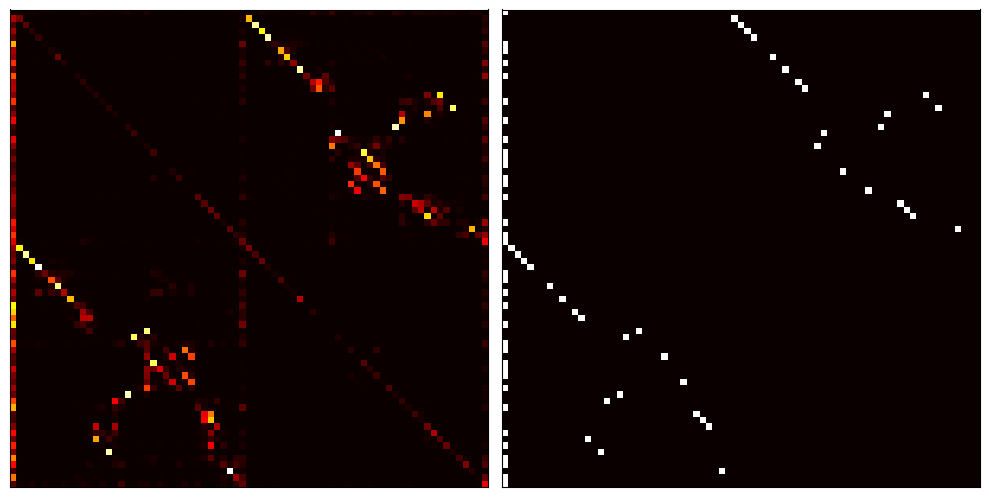

In [6]:
example_idx = 10
example_sample = data.iloc[example_idx].rxn
example_full_attention_map = data.iloc[example_idx].full_rxn_maps

example_sample = tokenizer(example_sample, add_special_tokens=True)
input_ids = torch.tensor(example_sample["input_ids"]).unsqueeze(0)
attention_mask = torch.tensor(example_sample["attention_mask"]).unsqueeze(0)


# Setup forward pass:
model.eval()
outputs = model(
    input_ids=input_ids,
    attention_mask=attention_mask,
    output_attentions=True,
)

# Plot output of model:
layer = 10
head = 5


fig, axs = plt.subplots(1, 2, figsize=(10, 10))

# attn_output = outputs.attentions[layer][0][head]
example_full_attention_map_to_plot = create_plottable_full_attn_map(
    example_full_attention_map
)
attn_output = outputs.attentions[layer][0][head]
plot_attn(attn_output, ax=axs[0])
plot_attn(example_full_attention_map_to_plot, ax=axs[1])
plt.tight_layout()

#### Observations: 

- We can see that the mapping makes sense. When compared to the groud truth its pretty good already. 
- My hypothesis is that if we make this attention head even sparser, the model might potentially be better. 

### Simple function to check how many predicitons are correct: 

- Does not account for just the product tokens

In [7]:
attn_output = outputs.attentions[layer][0][head]
attn_output = attn_output.detach().numpy().argmax(axis=1)
example_full_attention_map = np.array(example_full_attention_map)

# Remove all un-necessary tokens:
attn_output_cleaned = np.where(example_full_attention_map != 0, attn_output, 0)
print(attn_output_cleaned)
print(example_full_attention_map)

# Get total accuracy:
correct = np.sum(attn_output_cleaned == example_full_attention_map)
correct / len(example_full_attention_map)

[ 0 37 38 39 40  0  0 43  0 45  0 48 48 67  0 69 65  0 60 51  0 50  0  0
  0 58  0  0 58  0 63 66 65  0 72  0  0  1  2  3  4  0  0  7  0  9  0  0
  0  0 21 19  0  0 28  0  0  0 28  0 18  0  0 31 31 13  0 13  0 15  0  0
 34  0  0]
[ 0 36 37 38 39  0  0 42  0 44  0 46 47 66  0 68 60  0 59 50  0 49  0  0
  0 53  0  0 57  0 62 63 64  0 71  0  0  1  2  3  4  0  0  7  0  9  0 11
 12  0 21 19  0  0 25  0  0  0 28  0 18 16  0 30 31 32  0 13  0 15  0  0
 34  0  0]


0.6533333333333333

## Next steps: 

1. Analyse when the ground truth product mapping is wrong
2. See if we can implement a loss function on this mapping 
    2.1 currently thinking of doing a simple cross entropy loss.
    2.2 Eval if the attn in that head is any different/cleaner after.
3. Assess whether or not this approach is a feasible supervised learning. 

## 2. Implementing a simple finetuning of the mapper attention head:

In [8]:
# Visualization for a specific example
def visualize_attention(model, example_idx, layer_to_use=10, head_to_use=6):
    example_sample = data.iloc[example_idx].rxn
    example_full_attention_map = data.iloc[example_idx].full_rxn_maps

    tokenized = tokenizer(example_sample, add_special_tokens=True, return_tensors="pt")
    input_ids = tokenized["input_ids"].to("cuda")
    attention_mask = tokenized["attention_mask"].to("cuda")

    model.eval()
    with torch.no_grad():
        outputs = model(
            input_ids=input_ids, attention_mask=attention_mask, output_attentions=True
        )
        attn_output = outputs.attentions[layer_to_use][0][head_to_use].cpu()

    example_full_attention_map = create_plottable_full_attn_map(
        example_full_attention_map
    )

    # Plot
    fig, axs = plt.subplots(1, 2, figsize=(10, 5))
    plot_attn(attn_output, ax=axs[0])
    plot_attn(example_full_attention_map, ax=axs[1])
    plt.tight_layout()
    plt.show()
    model.train()


class ReactionDataset(Dataset):
    def __init__(self, data, tokenizer):
        self.data = data
        self.tokenizer = tokenizer

        # restrict to Subset of dataset:
        self.data = self.data[:1_000]

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        sample = self.data.iloc[idx].rxn
        full_attention_map = self.data.iloc[idx].full_rxn_maps

        # Tokenize sample
        tokenized = self.tokenizer(sample, add_special_tokens=True, return_tensors="pt")
        input_ids = tokenized["input_ids"].squeeze(0)
        attention_mask = tokenized["attention_mask"].squeeze(0)

        return input_ids.tolist(), attention_mask.tolist(), full_attention_map


# Collate function for padding
def collate_fn(batch):
    input_ids, attention_mask, full_attention_map = zip(*batch)

    max_len = max(len(ids) for ids in input_ids)

    # Pad sequences
    input_ids = [ids + [0] * (max_len - len(ids)) for ids in input_ids]
    attention_mask = [mask + [0] * (max_len - len(mask)) for mask in attention_mask]
    full_attention_map = [
        f_map + [0] * (max_len - len(f_map)) for f_map in full_attention_map
    ]

    return (
        torch.tensor(input_ids),
        torch.tensor(attention_mask),
        torch.tensor(full_attention_map),
    )

# Setup a simple training loop: 


## 2 Loss functions have been implemented: 

As we are using the output of an attention head, the values are already softmaxed. This means they canno tbe inputted straight into torch cross-entropy. I implemented 2 adaptations of cross entropy to be able to use it as a loss function. 

1. The first basically calculates the cross-entropy function without applying softmax. 

    - For some reason the range of this loss compared to the torch cross entropy is different. Implementation was quite rapid and could potentially include bugs. TODO: Double check it. 

2. The second we log the probabilities - turning back to somewhat logits looking values, and the apply the torch cross-entropy criterion

Before training:


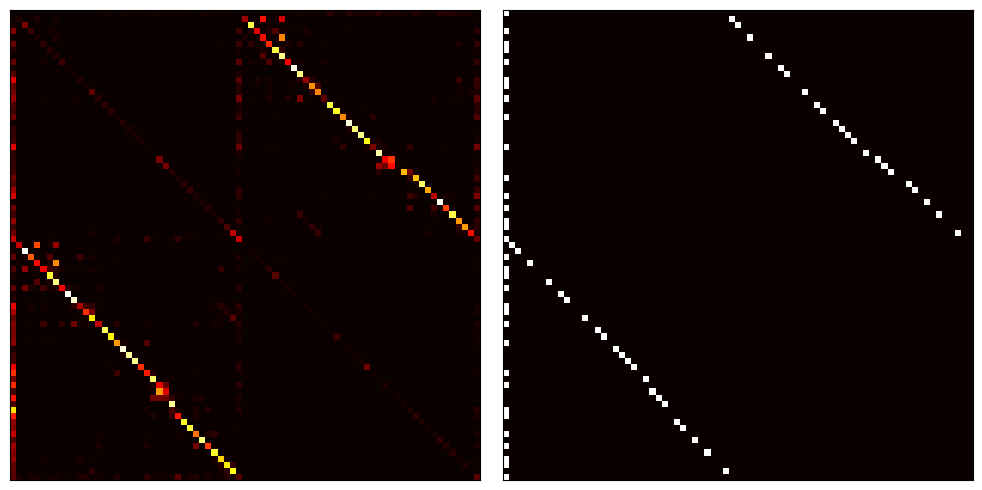

Starting training...
Epoch 1/50 completed. Average Loss: 3.9234
Epoch 2/50 completed. Average Loss: 3.0381
Epoch 3/50 completed. Average Loss: 2.6884
Epoch 4/50 completed. Average Loss: 2.4606
Epoch 5/50 completed. Average Loss: 2.2854
Epoch 6/50 completed. Average Loss: 2.1189


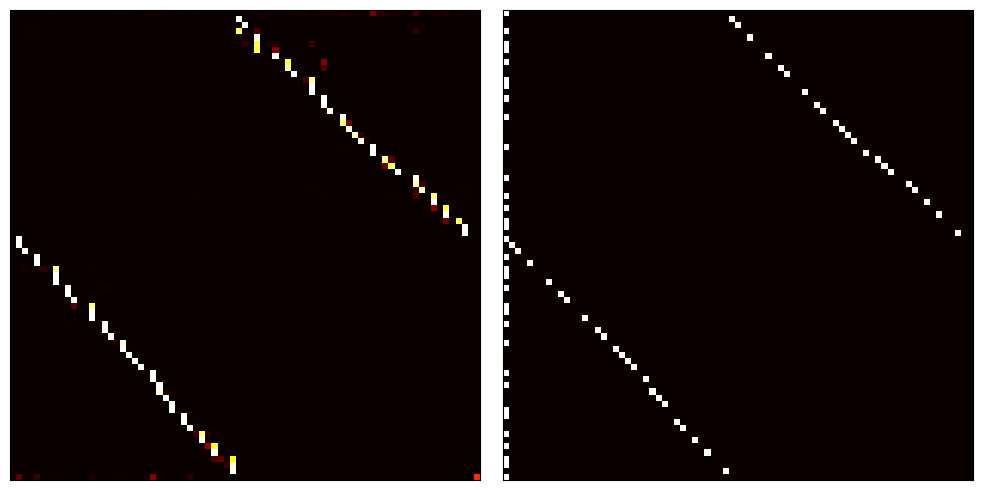

Epoch 7/50 completed. Average Loss: 2.0346
Epoch 8/50 completed. Average Loss: 1.9006
Epoch 9/50 completed. Average Loss: 1.7285
Epoch 10/50 completed. Average Loss: 1.6192
Epoch 11/50 completed. Average Loss: 1.5259


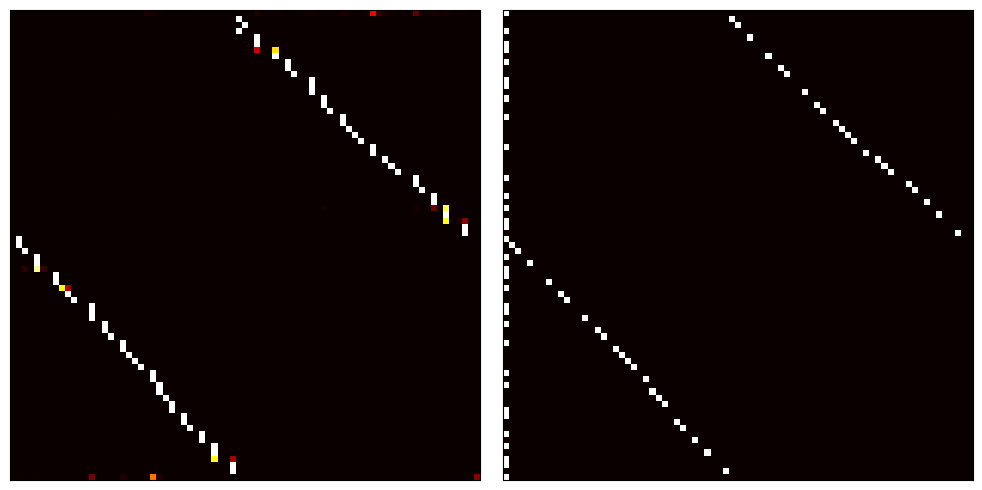

Epoch 12/50 completed. Average Loss: 1.3697
Epoch 13/50 completed. Average Loss: 1.2928
Epoch 14/50 completed. Average Loss: 1.2276
Epoch 15/50 completed. Average Loss: 1.1723
Epoch 16/50 completed. Average Loss: 1.1221


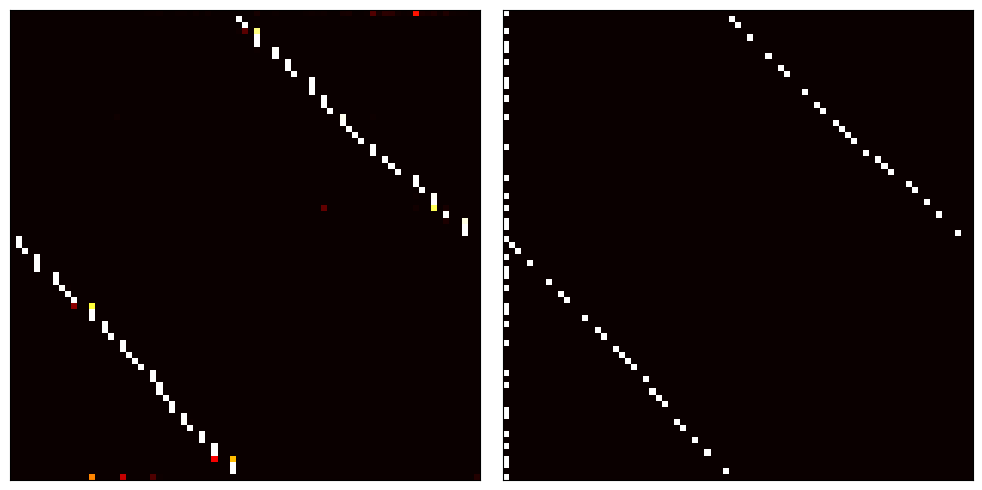

Epoch 17/50 completed. Average Loss: 1.0889
Epoch 18/50 completed. Average Loss: 1.0389
Epoch 19/50 completed. Average Loss: 1.0374
Epoch 20/50 completed. Average Loss: 1.0026
Epoch 21/50 completed. Average Loss: 0.9561


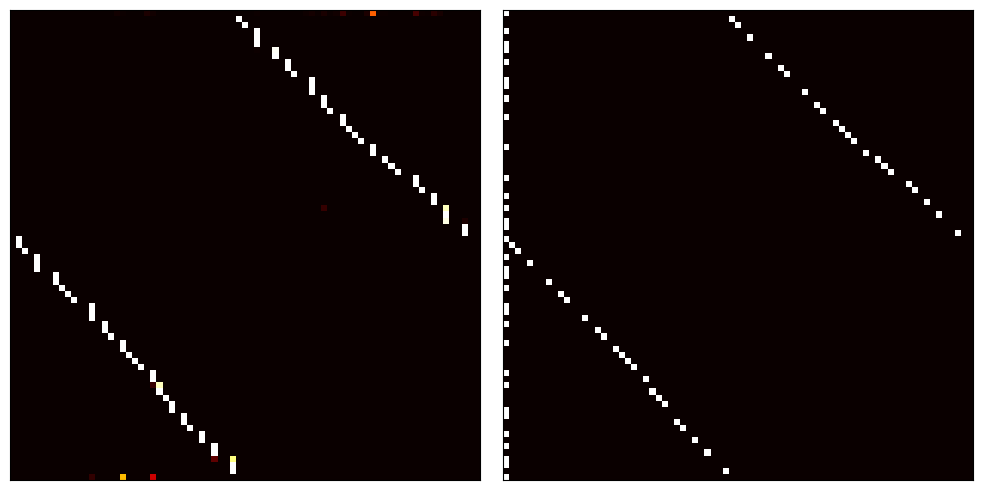

Epoch 22/50 completed. Average Loss: 0.9813
Epoch 23/50 completed. Average Loss: 0.9327
Epoch 24/50 completed. Average Loss: 0.9192
Epoch 25/50 completed. Average Loss: 0.9314
Epoch 26/50 completed. Average Loss: 0.8886


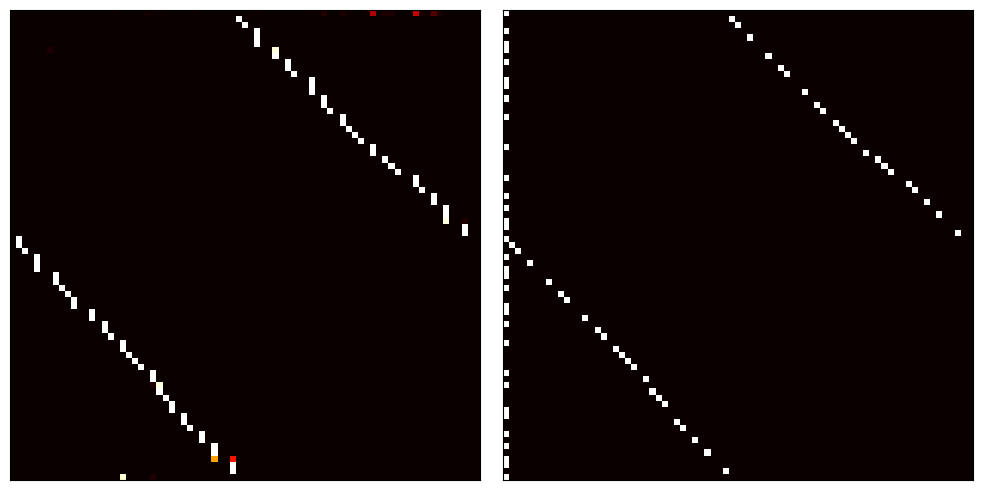

Epoch 27/50 completed. Average Loss: 0.8995
Epoch 28/50 completed. Average Loss: 0.8737
Epoch 29/50 completed. Average Loss: 0.8604
Epoch 30/50 completed. Average Loss: 0.8511
Epoch 31/50 completed. Average Loss: 0.8524


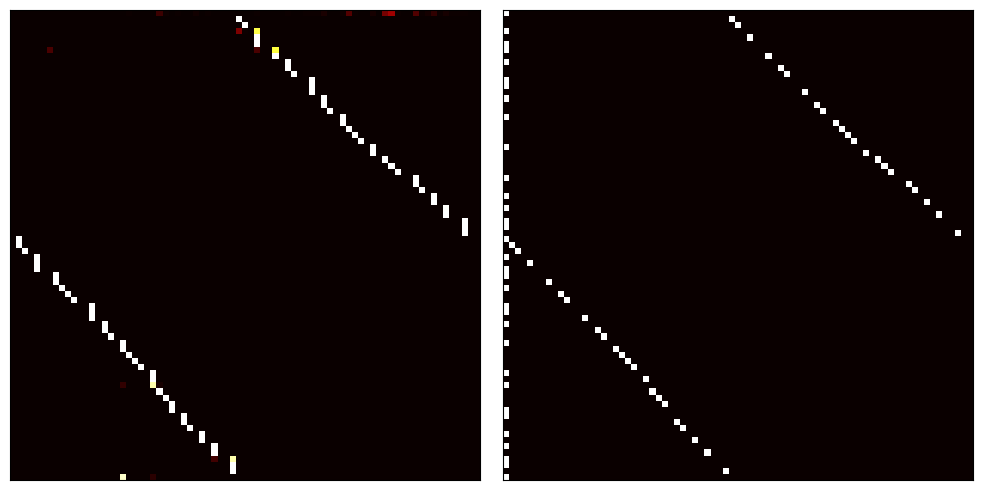

Epoch 32/50 completed. Average Loss: 0.8484
Epoch 33/50 completed. Average Loss: 0.8321
Epoch 34/50 completed. Average Loss: 0.8159
Epoch 35/50 completed. Average Loss: 0.8015
Epoch 36/50 completed. Average Loss: 0.7890


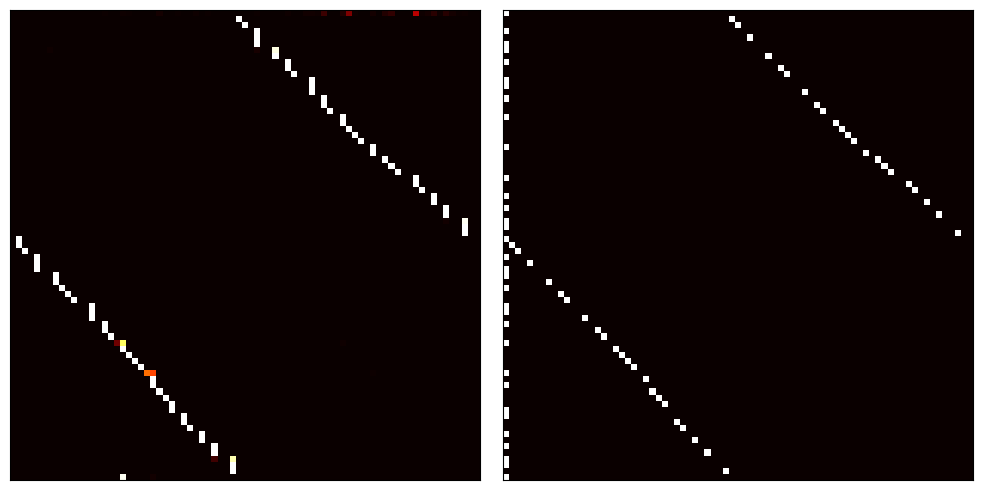

Epoch 37/50 completed. Average Loss: 0.8004
Epoch 38/50 completed. Average Loss: 0.7812
Epoch 39/50 completed. Average Loss: 0.7979
Epoch 40/50 completed. Average Loss: 0.7982
Epoch 41/50 completed. Average Loss: 0.7778


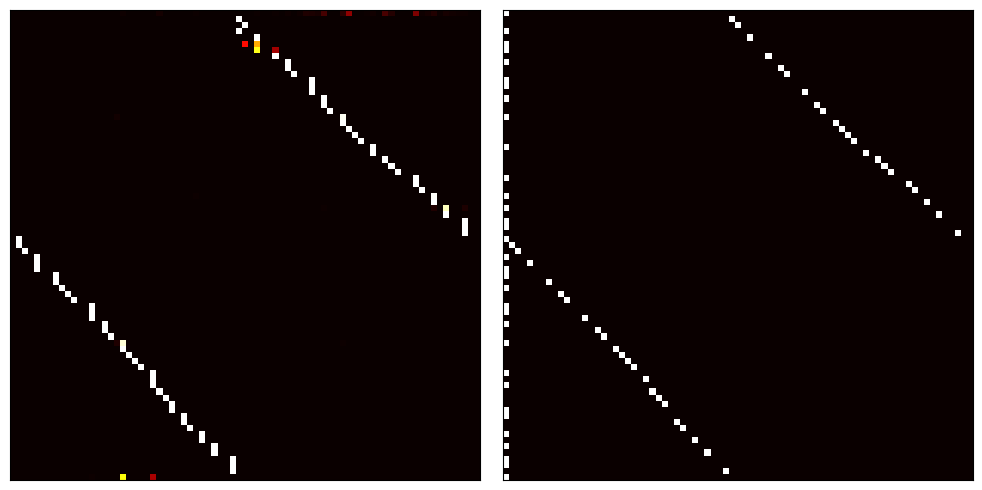

Epoch 42/50 completed. Average Loss: 0.7649
Epoch 43/50 completed. Average Loss: 0.7678
Epoch 44/50 completed. Average Loss: 0.7414
Epoch 45/50 completed. Average Loss: 0.7412
Epoch 46/50 completed. Average Loss: 0.7516


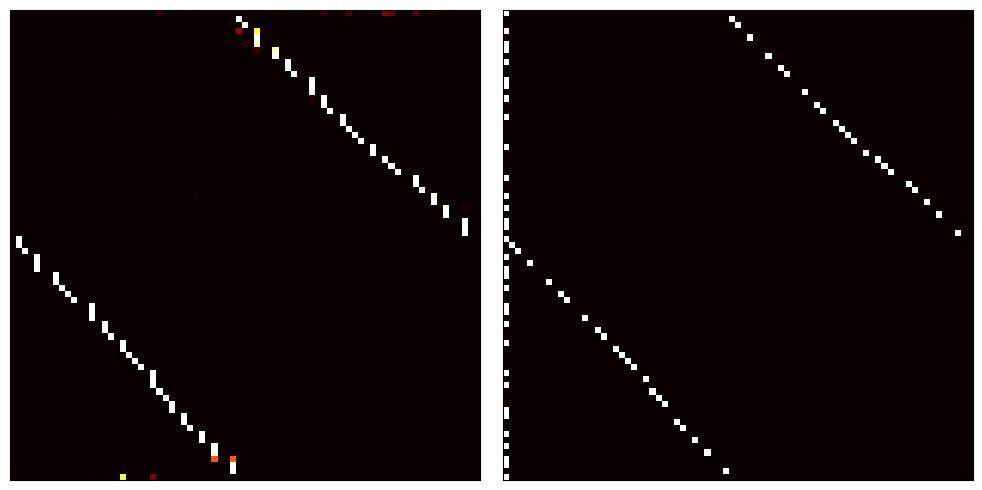

Epoch 47/50 completed. Average Loss: 0.7797
Epoch 48/50 completed. Average Loss: 0.7550
Epoch 49/50 completed. Average Loss: 0.7502
Epoch 50/50 completed. Average Loss: 0.7507
Training completed.


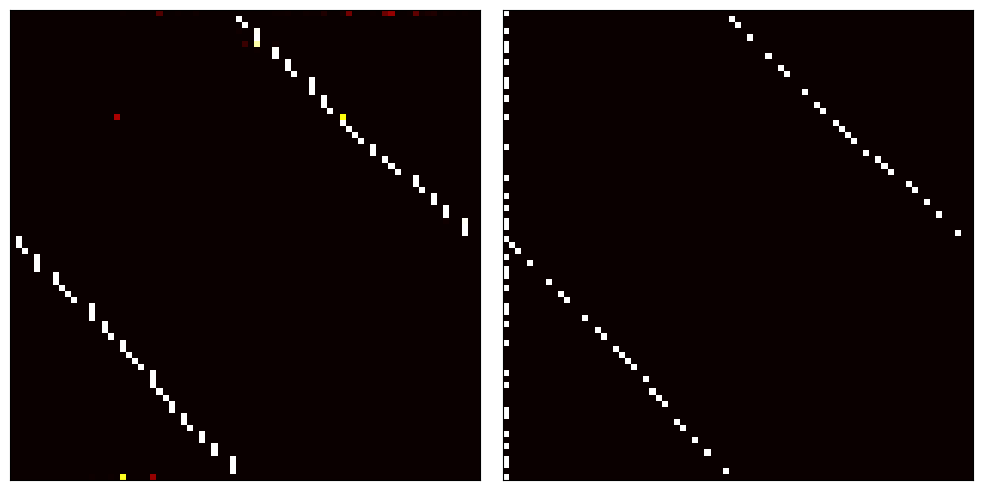

In [9]:
# Simple Parameters
layer_to_use, head_to_use = 10, 5
lr = 1e-4
batch_size = 32
epochs = 50

optimizer = torch.optim.Adam(model.parameters(), lr=lr)


# Setup Data:
dataset = ReactionDataset(data, tokenizer)
dataloader = DataLoader(
    dataset, batch_size=batch_size, shuffle=True, collate_fn=collate_fn
)


# Print before training:
print("Before training:")
model = model.to("cuda")
visualize_attention(
    model=model, example_idx=90, layer_to_use=layer_to_use, head_to_use=head_to_use
)
model.train()


def cross_entropy_loss_softmaxed(predictions, labels_, ignore_index=-100):
    """
    Computes cross-entropy loss for softmaxed predictions in PyTorch.

    Args:
        predictions (torch.Tensor): Softmaxed predictions, shape (N, C).
        labels (torch.Tensor): One-hot encoded labels, shape (N, C).

    Returns:
        torch.Tensor: Cross-entropy loss.
    """

    batch_size, seq_len, _ = predictions.shape
    predictions = predictions.reshape(batch_size * seq_len, seq_len)

    # Turn into labels:
    labels = torch.nn.functional.one_hot(
        labels_,
        num_classes=labels_.shape[1],
    )
    labels = labels.reshape(batch_size * seq_len, seq_len)

    # Create mask for non-ignored indices
    mask = (labels_ != ignore_index).view(batch_size * seq_len)

    # Avoid log(0) by clipping
    epsilon = 1e-10
    predictions = torch.clamp(predictions, min=epsilon, max=1.0)

    # Apply mask to labels and predictions
    masked_labels = labels[mask]
    masked_predictions = predictions[mask]

    # Compute cross-entropy loss
    loss = -torch.sum(
        masked_labels * torch.log(masked_predictions)
    ) / masked_predictions.size(0)
    return loss


def cross_entropy_loss_softmaxed_using_func(predictions, labels_, ignore_index=0):
    """
    Computes cross-entropy loss using PyTorch's built-in function for pre-softmaxed predictions.

    Args:
        predictions (torch.Tensor): Softmaxed predictions, shape (N, T, C).
        labels_ (torch.Tensor): Integer class labels, shape (N, T).
        ignore_index (int): Index to ignore when computing loss.

    Returns:
        torch.Tensor: Cross-entropy loss.
    """
    # Avoid log(0) by clamping softmaxed predictions
    epsilon = 1e-10
    predictions = torch.clamp(predictions, min=epsilon, max=1.0)

    # Convert softmax probabilities to logits
    logits = torch.log(predictions)

    # Reshape logits and labels for cross-entropy
    batch_size, seq_len, num_classes = logits.shape
    logits = logits.view(-1, num_classes)  # Shape (N*T, C)
    labels_ = labels_.view(-1)  # Shape (N*T)

    # Compute cross-entropy loss
    loss = torch.nn.functional.cross_entropy(
        logits,
        labels_,
        ignore_index=ignore_index,
        reduction="mean",  # Compute mean loss over valid elements
    )
    return loss


# Forward pass function
def forward_pass(batch, model, optimizer, criterion, layer_to_use, head_to_use):
    """
    Executes a forward pass, computes the loss, and performs backpropagation.

    Args:
        batch (tuple): A batch of input_ids, attention_mask, and full_attention_map.
        model (torch.nn.Module): The model being trained.
        optimizer (torch.optim.Optimizer): Optimizer for updating model weights.
        criterion (torch.nn.Module): Loss function.
        layer_to_use (int): Layer index to use for attention extraction.
        head_to_use (int): Head index to use for attention extraction.

    Returns:
        float: The computed loss for the batch.
    """
    input_ids, attention_mask, full_attention_map = batch

    # Move data to GPU
    input_ids, attention_mask, full_attention_map = (
        input_ids.to("cuda"),
        attention_mask.to("cuda"),
        full_attention_map.to("cuda"),
    )

    optimizer.zero_grad()
    outputs = model(
        input_ids=input_ids, attention_mask=attention_mask, output_attentions=True
    )
    attn_output = outputs.attentions[layer_to_use][:, head_to_use]

    # Compute loss
    loss = criterion(attn_output, full_attention_map)
    loss.backward()
    optimizer.step()
    return loss.item()


# Training loop
print("Starting training...")
for epoch in range(epochs):
    epoch_loss = 0.0

    for batch_idx, batch in enumerate(dataloader):
        loss = forward_pass(
            batch,
            model,
            optimizer,
            cross_entropy_loss_softmaxed_using_func,
            layer_to_use,
            head_to_use,
        )
        epoch_loss += loss
    print(
        f"Epoch {epoch + 1}/{epochs} completed. Average Loss: {epoch_loss / len(dataloader):.4f}"
    )
    if epoch % 5 == 0 and epoch != 0:
        visualize_attention(
            model=model,
            example_idx=90,
            layer_to_use=layer_to_use,
            head_to_use=head_to_use,
        )

print("Training completed.")
visualize_attention(
    model=model, example_idx=90, layer_to_use=layer_to_use, head_to_use=head_to_use
)

In [10]:
# Save model:
model.save_pretrained(
    "../trained_models/finetuned_v1_model_on_1000_cyclisations_ft_33_epochs_ALL_reactions"
)

# Copy the vocab file :) WOuld be nice to save it automatically:
shutil.copy(
    "../rxnmapper/models/transformers/albert_heads_8_uspto_all_1310k/vocab.txt",
    "../trained_models/finetuned_v1_model_on_1000_cyclisations_ft_33_epochs_ALL_reactions",
)

'../trained_models/finetuned_v1_model_on_1000_cyclisations_ft_33_epochs_ALL_reactions/vocab.txt'